In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.impute import SimpleImputer
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, r2_score, root_mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import plot_tree
from sklearn.model_selection import GridSearchCV

In [2]:
df = pd.read_csv(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Data\Processed\cleaned_dataset.csv")

df.head()

,Latitude,Longitude,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed,LULC_Name
0,28.632720,77.204349,32.490555,1065.082156,223,28.763419,41.820506,6,-0.103358,-0.061668,0.161954,190.287857,3.489779,1.422401,Built Area
1,28.614477,77.114090,32.618237,4417.420062,219,28.276358,46.014417,6,-0.089072,-0.004090,0.071271,318.664734,1.854334,1.422094,Built Area
2,28.783908,77.106962,32.277801,56.568542,211,29.923939,44.336169,0,-0.086957,-0.014011,0.089721,0.000000,1.406886,1.355455,Water
3,28.660692,77.147372,32.479869,1059.056184,216,29.162266,45.623053,6,-0.079266,-0.051205,0.125391,268.919067,2.307262,1.391453,Built Area
4,28.814437,76.991782,32.366906,1223.764683,226,29.204621,50.153639,7,-0.151679,0.025338,0.100419,0.000000,4.263645,1.359317,Bare Ground


In [3]:
df = df.drop(columns=["LULC"])

In [4]:
# One hot encoding
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[["LULC_Name"]])

In [5]:
encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["LULC_Name"]),
    index = df.index
)

In [6]:
df = pd.concat([df.drop(columns=["LULC_Name"]),encoded_df], axis=1)

In [7]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope',
       'WindSpeed', 'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='object')

In [8]:
X = df.drop(columns=["LST"])
y = df["LST"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [10]:
model = DecisionTreeRegressor()
model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [11]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

In [12]:
print(f"MSE of training data = {mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

MSE of training data = 0.0
MSE of testing data = 3.831212724920981
r2_score of training data = 1.0
r2_score of testing data = 0.6598084506018449


## The above model is highly overfit

In [13]:
full_tree = DecisionTreeRegressor(random_state=42, max_depth=15, min_samples_split=10)
full_tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,15
,min_samples_split,10
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [14]:
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alpha = path.ccp_alphas
# ccp_alpha = ccp_alpha[::10]
ccp_alpha.shape

(986,)

In [15]:
param_grid = {"ccp_alpha" : ccp_alpha}
classifier = full_tree
grid_search = GridSearchCV(
    classifier,
    param_grid,
    scoring = "r2",
    cv = 5
)
grid_search.fit(X_train, y_train)
best_r2_score = grid_search.best_score_
best_alpha = grid_search.best_params_['ccp_alpha']

In [16]:
print(best_r2_score)
print(best_alpha)

0.7649696746045374
0.0036566333074065697


In [21]:
best_model = DecisionTreeRegressor(random_state=42, max_depth=15, min_samples_split=10, ccp_alpha=best_alpha)
best_model.fit(X_train, y_train)

y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)

print(f"MSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"MSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

MSE of training data = 1.3631034484530866
MSE of testing data = 1.6130920723879196
r2_score of training data = 0.839448671414415
r2_score of testing data = 0.7689502151668474


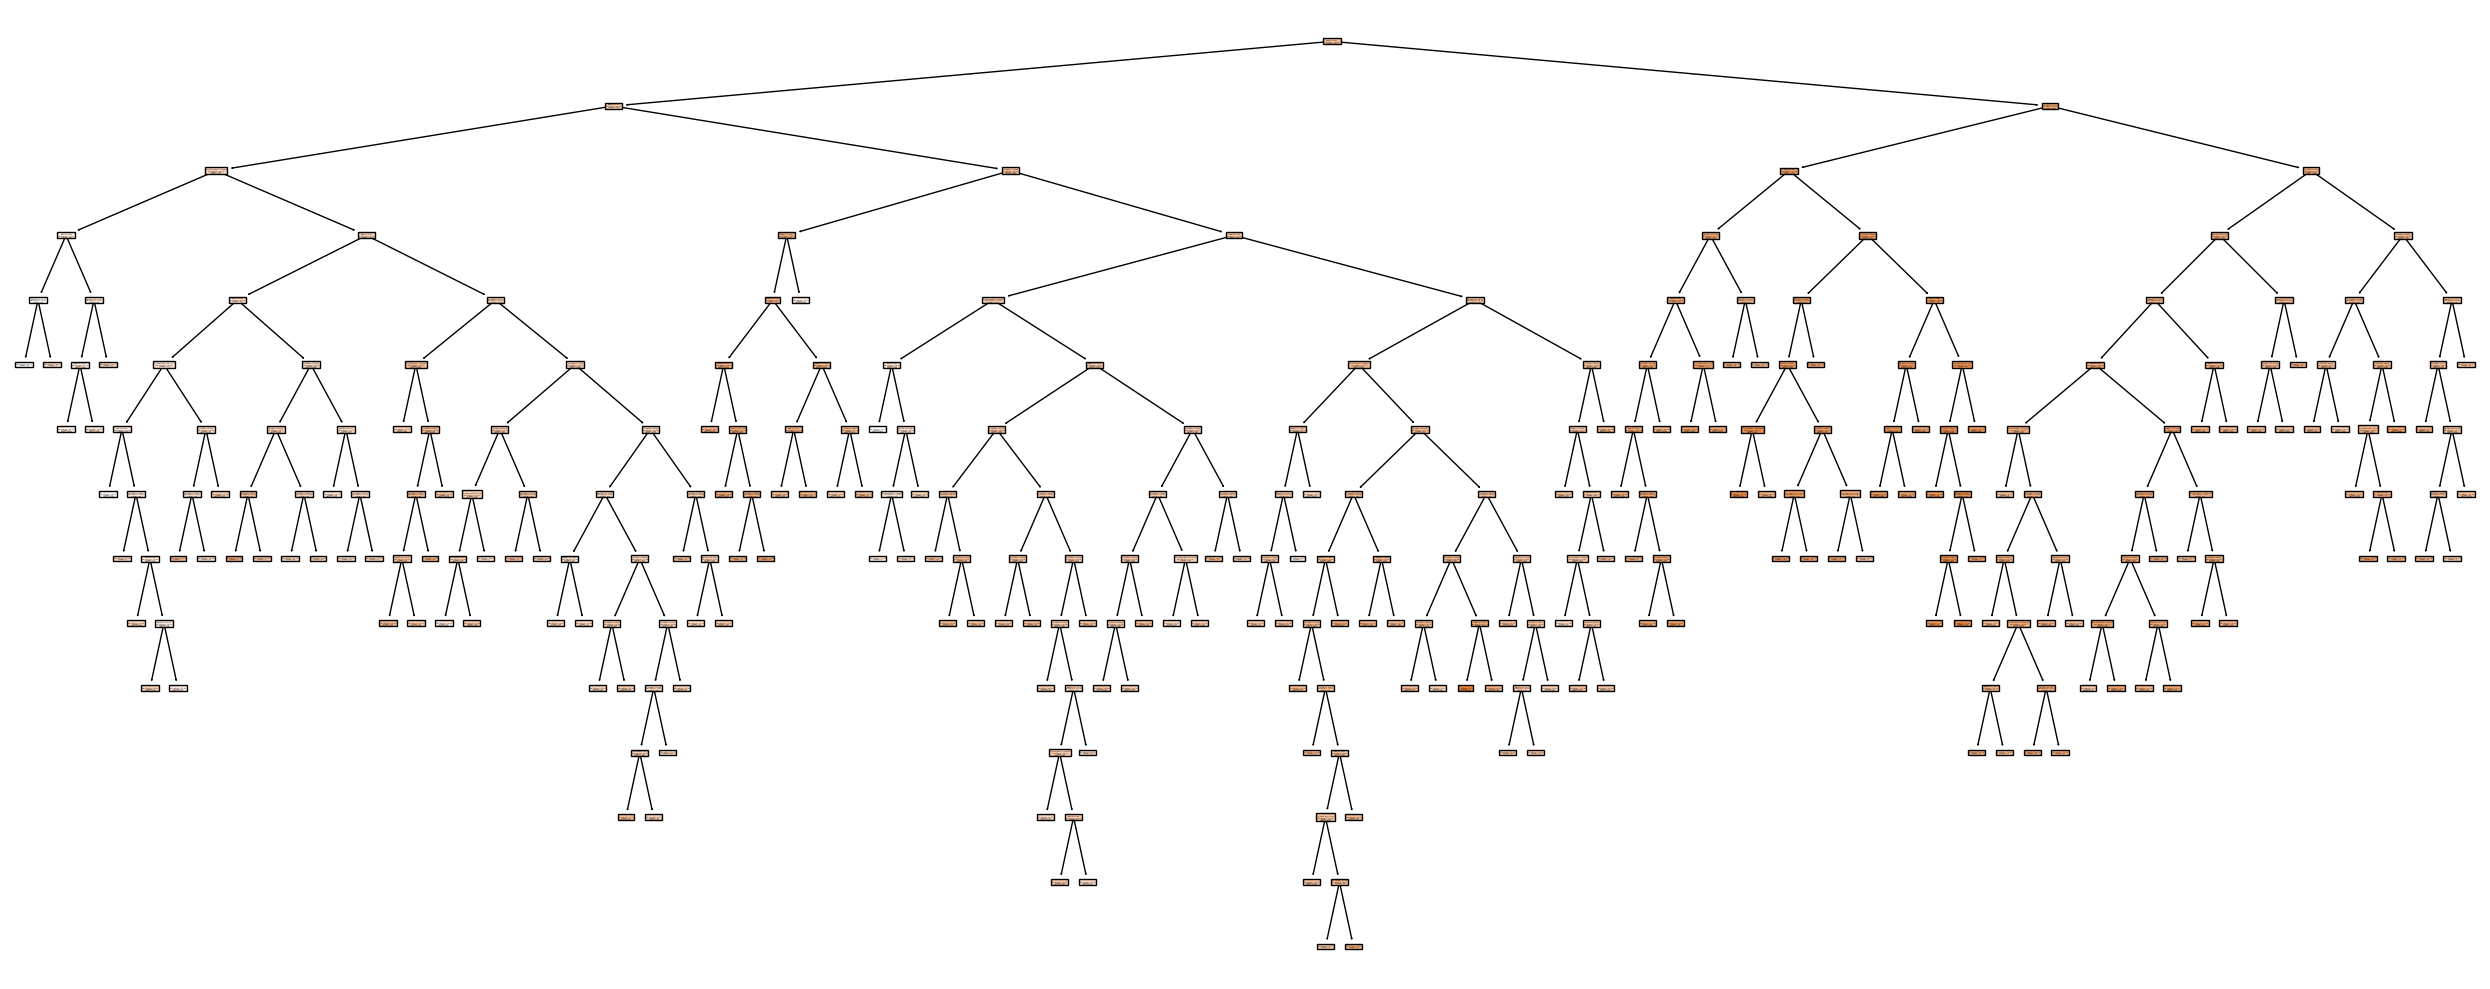

In [18]:
plt.figure(figsize=(25,10))
plot_tree(
    best_model,
    feature_names=X.columns,
    filled=True
)
plt.tight_layout()
plt.show()